Dataset Shape: (2059, 20)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   object 
 1   Model               2059 non-null   object 
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   object 
 6   Transmission        2059 non-null   object 
 7   Location            2059 non-null   object 
 8   Color               2059 non-null   object 
 9   Owner               2059 non-null   object 
 10  Seller Type         2059 non-null   object 
 11  Engine              1979 non-null   object 
 12  Max Power           1979 non-null   object 
 13  Max Torque          1979 non-null   object 
 14  Drivetrain          1923 non-null   object 
 15  Length        

,Price,Year,Kilometer,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
count,2.059000e+03,2059.000000,2.059000e+03,1995.000000,1995.000000,1995.000000,1995.000000,1946.000000
mean,1.702992e+06,2016.425449,5.422471e+04,4280.860652,1767.991980,1591.735338,5.306266,52.002210
std,2.419881e+06,3.363564,5.736172e+04,442.458507,135.265825,136.073956,0.822170,15.110198
min,4.900000e+04,1988.000000,0.000000e+00,3099.000000,1475.000000,1165.000000,2.000000,15.000000
25%,4.849990e+05,2014.000000,2.900000e+04,3985.000000,1695.000000,1485.000000,5.000000,41.250000
50%,8.250000e+05,2017.000000,5.000000e+04,4370.000000,1770.000000,1545.000000,5.000000,50.000000
75%,1.925000e+06,2019.000000,7.200000e+04,4629.000000,1831.500000,1675.000000,5.000000,60.000000
max,3.500000e+07,2022.000000,2.000000e+06,5569.000000,2220.000000,1995.000000,8.000000,105.000000



Missing Values :
Make                    0
Model                   0
Price                   0
Year                    0
Kilometer               0
Fuel Type               0
Transmission            0
Location                0
Color                   0
Owner                   0
Seller Type             0
Engine                 80
Max Power              80
Max Torque             80
Drivetrain            136
Length                 64
Width                  64
Height                 64
Seating Capacity       64
Fuel Tank Capacity    113
dtype: int64


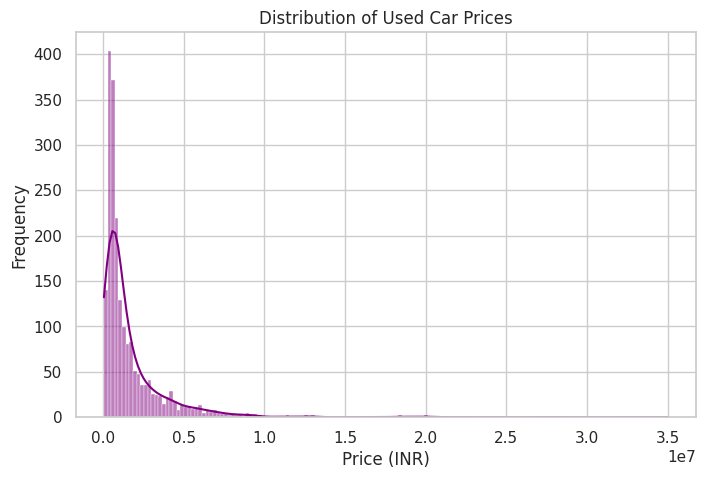

In [13]:
# 1. Data Exploration

# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Load the dataset
df = pd.read_csv('car details v4.csv')

# structure of the dataset
print("Dataset Shape:", df.shape)
print("\nDataset Info:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

# Missing values
print("\nMissing Values :")
print(df.isnull().sum())

# Plot distribution of the target variable (Price)
plt.figure(figsize=(8, 5))
sns.histplot(df['Price'], kde=True, color='purple')
plt.title('Distribution of Used Car Prices')
plt.xlabel('Price (INR)')
plt.ylabel('Frequency')
plt.show()

In [14]:
# 2. Data Preprocessing

# To clean columns with text units
def clean_numeric_string(val):
    if pd.isna(val):
        return np.nan
    # Extract the first continuous number found in the string
    import re
    numbers = re.findall(r"[-+]?\d*\.\d+|\d+", str(val))
    return float(numbers[0]) if numbers else np.nan

# Clean specific columns if they exist
if 'Engine' in df.columns:
    df['Engine'] = df['Engine'].apply(clean_numeric_string)
if 'Max Power' in df.columns:
    df['Max Power'] = df['Max Power'].apply(clean_numeric_string)
if 'Max Torque' in df.columns:
    df['Max Torque'] = df['Max Torque'].apply(clean_numeric_string)

# Separate features (X) and target variable (y)
# Drop 'Model'
X = df.drop(columns=['Price', 'Model'])
y = df['Price']

# Identify numeric and categorical features
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object', 'category']).columns

print("Numerical Features:", list(numeric_features))
print("Categorical Features:", list(categorical_features))


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

Numerical Features: ['Year', 'Kilometer', 'Engine', 'Max Power', 'Max Torque', 'Length', 'Width', 'Height', 'Seating Capacity', 'Fuel Tank Capacity']
Categorical Features: ['Make', 'Fuel Type', 'Transmission', 'Location', 'Color', 'Owner', 'Seller Type', 'Drivetrain']


In [15]:
# 3. Model Development

from sklearn.linear_model import LinearRegression

# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# containing preprocessor and the Linear Regression model
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Train the model
model.fit(X_train, y_train)
print("Model training completed successfully")

Model training completed successfully


Mean Squared Error (MSE): 2,309,255,905,571.45
Root Mean Squared Error (RMSE): ₹1,519,623.61
R-squared (R2 Score): 0.6695


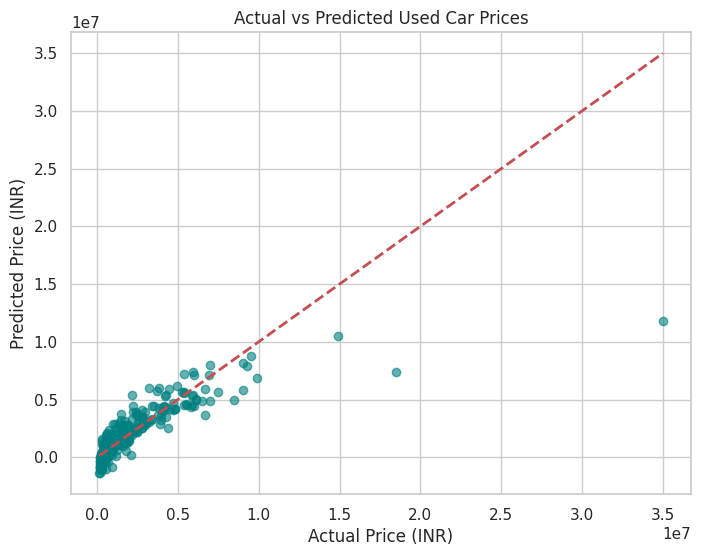

In [16]:
# 4. Evaluate the model's performance

from sklearn.metrics import mean_squared_error, r2_score

# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): ₹{rmse:,.2f}")
print(f"R-squared (R2 Score): {r2:.4f}")

# Visualization: Actual vs Predicted Prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price (INR)')
plt.ylabel('Predicted Price (INR)')
plt.title('Actual vs Predicted Used Car Prices')
plt.show()

• Provide interpretations of the model's findings.

**Model Accuracy (R2 Score):**
Model achieved an R-squared score of 0.6695. This means 67% of the variation in used car prices can be explained by our features. The remaining 33% is influenced by factors not captured in the dataset, such as the car's physical condition, market demand, or service history.  
**Prediction Error (RMSE):**
The Root Mean Squared Error (RMSE) is ₹1,519,623.61. Model's price predictions have an error margin of about ₹15.2 lakhs.